In [49]:
import numpy as np
import matplotlib.pyplot as plt

In [50]:
%%time
N = 1234
W0 = np.eye(N)
I = np.tril(np.ones((N,N)))

CPU times: user 6.1 ms, sys: 10.1 ms, total: 16.2 ms
Wall time: 13.2 ms


In [51]:
%%time
W1 = I @ W0 @ I.T
W2 = I @ W1 @ I.T

CPU times: user 1.32 s, sys: 40.9 ms, total: 1.36 s
Wall time: 200 ms


In [52]:
%%time
W2ch = np.linalg.cholesky(W2)

CPU times: user 157 ms, sys: 22.2 ms, total: 179 ms
Wall time: 28.3 ms


In [53]:
%%time
S11 = W2[:-1, :-1]
S12 = W2[-1:, :-1]
S22 = W2[-1:, -1:]
S22i = np.linalg.inv(S22)
S21 = W2[:-1, -1:]

CPU times: user 2.08 ms, sys: 13.1 ms, total: 15.2 ms
Wall time: 2.05 ms


In [54]:
%%time
Sm = S11 - S21 @ S22i @ S12
SmCH = np.linalg.cholesky(Sm)

CPU times: user 99.5 ms, sys: 6.45 ms, total: 106 ms
Wall time: 23.8 ms


In [55]:
%%time
mum = S21@S22i

CPU times: user 172 µs, sys: 587 µs, total: 759 µs
Wall time: 121 µs


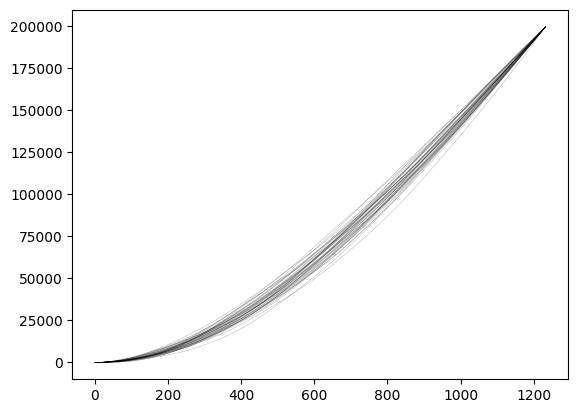

In [56]:
n = 40
w = np.random.randn(N-1, n)
a = np.pad(SmCH @ w + mum * 200000, ((1,0),(0,0)))
plt.plot(a, 'k', alpha=0.5, linewidth=0.2)
plt.show()

In [57]:
da = np.pad(np.diff(a, axis=0), ((1,0),(0,0)))

In [58]:
dda = np.diff(da, axis=0)

In [59]:
dda.shape

(1233, 40)

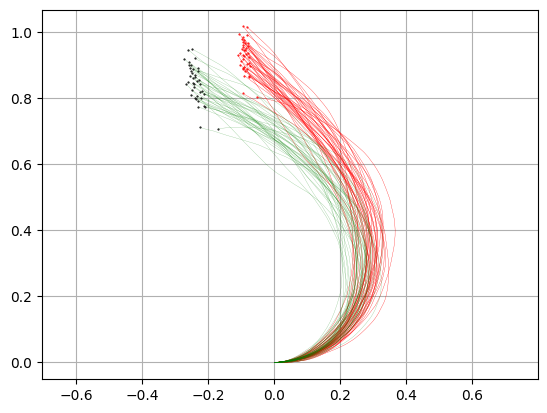

In [60]:
x = np.zeros(n)
y = np.zeros(n)
phi = np.zeros(n)

dt = 1e-3
v = 1
Dr = 1e-1
traj = []
for i in range(dda.shape[0]):
    dx = np.cos(phi)
    dy = np.sin(phi)
    
    x += dx * dt
    y += dy * dt
    phi += np.sqrt(Dr * dt) * dda[i,:]
    
    traj.append(np.stack([x,y]))
    

traj = np.stack(traj)   
plt.plot(traj[:,0,:], traj[:,1,:], 'r', alpha=1, linewidth=0.2)

plt.gca().axis('equal')

x1 = x
y1 = y

x = np.zeros(n)
y = np.zeros(n)
phi = np.zeros(n)

dt = 1e-3
v = 1
Dr *= 1.1
traj = []
for i in range(dda.shape[0]):
    dx = np.cos(phi)
    dy = np.sin(phi)
    
    x += dx * dt
    y += dy * dt
    phi += np.sqrt(1.1*Dr * dt) * dda[i,:]
    
    traj.append(np.stack([x,y]))
    
x2 = x
y2 = y
traj = np.stack(traj)   
plt.plot(traj[:,0,:], traj[:,1,:], 'g', alpha=0.5, linewidth=0.2)
plt.plot(x1,y1, '.r', markersize=1)
plt.plot(x2,y2, '.k', markersize=1)
plt.gca().axis('equal')
plt.grid()

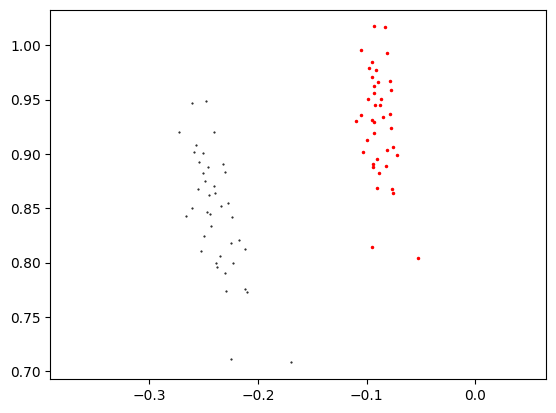

In [61]:
plt.plot(x1,y1, '.r', markersize=3)
plt.plot(x2,y2, '.k', markersize=1)
plt.gca().axis('equal')
plt.show()